# Experimentación de Modelos de NLP
**Asistente Inteligente para la Inspección Visual y Trazabilidad de Daños en Empaques**  

---

### Objetivo del cuaderno:
Este cuaderno implementa el ciclo completo de experimentación de Procesamiento de Lenguaje Natural (NLP) enfocado en **evaluaciones exclusivamente estratificadas** (*5-Fold Stratified Cross-Validation*):
1. **Carga y Análisis Exploratorio**: Dataset balanceado con 360 muestras reales y sintéticas distribuidas en 7 intenciones del proceso de almacén.
2. **Preprocesamiento NLP (4 técnicas)**: Normalización NFD (minúsculas, sin acentos), tokenización léxica, eliminación controlada de stopwords (protegiendo términos críticos como *sin*, *no*, *hasta*, *estado*) y stemming con Snowball en español.
3. **Matriz Experimental 2 × 2**:
   - **Representación**: Bag of Words (`CountVectorizer`) vs. **TF-IDF** (`TfidfVectorizer`).
   - **Clasificador**: **MultinomialNB (Naive Bayes)** vs. **LinearSVC (Support Vector Machines - SVM)**.
4. **Evaluación Exclusivamente Estratificada (5-Fold Stratified K-Fold)**:
   - Particionamiento estratificado con `StratifiedKFold` para preservar la distribución exacta de cada intención en cada pliegue.
   - Métricas ponderadas reportadas como **Media ± Desviación Estándar**: *Accuracy*, *Precision*, *Recall* y *F1-Score*.
5. **Reporte Detallado y Matrices de Confusión Estratificadas**:
   - Generación de predicciones fuera de pliegue (*out-of-fold*) mediante `cross_val_predict` sobre la totalidad del dataset (360 muestras evaluadas sin sesgo).
6. **Validación de Casos Límite (*Edge Cases*)**:
   - Erratas tipográficas y vocabulario fuera del diccionario que antes hacían fallar al motor de reglas del Avance 1.
7. **Exportación del Pipeline Ganador**:
   - Serialización con `joblib` para su integración directa en el motor conversacional desacoplado (`src/chatbot_engine.py`).


## 1. Carga y Exploración del Conjunto de Datos
Cargamos el conjunto de datos de intenciones (`data/dataset_intenciones.csv`) y verificamos su balanceo y estructura.


In [1]:
import pandas as pd

# Cargar dataset de intenciones de almacén
ruta_dataset = "data/dataset_intenciones.csv"
df = pd.read_csv(ruta_dataset)

print(f"Total de muestras registradas: {len(df)}")
print(f"Valores nulos por columna:\n{df.isnull().sum()}\n")

# Distribución por clase objetivo (intención)
print("Distribución de muestras por intención:")
display(df["intencion"].value_counts().reset_index().rename(columns={"intencion": "Intención", "count": "Total de Ejemplos"}))

print("\nPrimeras 5 observaciones del dataset:")
display(df.head())


Total de muestras registradas: 365
Valores nulos por columna:
texto        0
intencion    0
dtype: int64

Distribución de muestras por intención:


,Intención,Total de Ejemplos
0,reportar_dano_empaque,57
1,confirmar_empaque_intacto,54
2,consultar_politica_rechazo,53
3,iniciar_auditoria,51
4,saludo,50
5,despedida,50
6,fallback,50



Primeras 5 observaciones del dataset:


,texto,intencion
0,Hola buen día,saludo
1,Buenas tardes quiero iniciar turno,saludo
2,Hola bot,saludo
3,Buenos días,saludo
4,Saludos,saludo


## 2. Preprocesamiento de Lenguaje Natural (NLP)
Validamos las 4 técnicas de preprocesamiento requeridas por la rúbrica implementadas en `src/preprocessor.py`:
1. **Normalización NFD**: Remueve tildes, diéresis y signos de puntuación, convirtiendo a minúsculas.
2. **Tokenización léxica**: Separa palabras y números preservando la estructura oracional.
3. **Eliminación de Stopwords**: Descarga NLTK en español pero **protege** términos clave de dominio logístico (*sin*, *no*, *nada*, *hasta*, *estado*, *estados*, *contra*).
4. **Stemming (Snowball en español)**: Reduce flexiones a su raíz léxica (p. ej., *dañada*, *daños*, *dañadas* $\to$ *dañ*).


In [2]:
from functools import partial

from src.preprocessor import normalizar, preprocesar

ejemplo_texto = "¡Alerta! La caja 504 llegó con manchas de humedad y el sello violado en el andén 2."

print("1. Texto original                          :", ejemplo_texto)
print("2. Normalizado NFD                         :", normalizar(ejemplo_texto))
print("3. Preprocesado con stopwords (motor reglas):", preprocesar(ejemplo_texto, eliminar_stopwords=False))
print("4. Preprocesado sin stopwords (para ML)    :", preprocesar(ejemplo_texto, eliminar_stopwords=True))

# Tokenizador reutilizable para vectorizadores de scikit-learn
# Usamos functools.partial para garantizar compatibilidad con serialización joblib
tokenizer_ml = partial(preprocesar, eliminar_stopwords=True)


1. Texto original                          : ¡Alerta! La caja 504 llegó con manchas de humedad y el sello violado en el andén 2.
2. Normalizado NFD                         : alerta la caja 504 llego con manchas de humedad y el sello violado en el anden 2
3. Preprocesado con stopwords (motor reglas): ['alert', 'la', 'caj', '504', 'lleg', 'con', 'manch', 'de', 'humed', 'y', 'el', 'sell', 'viol', 'en', 'el', 'anden', '2']
4. Preprocesado sin stopwords (para ML)    : ['alert', 'caj', '504', 'lleg', 'manch', 'humed', 'sell', 'viol', 'anden', '2']


## 3. Matriz Experimental 2 × 2 (Pipelines de Clasificación)
Construimos los pipelines que combinan las 2 representaciones vectoriales con los 2 algoritmos de aprendizaje supervisado:
- **Bag of Words (`CountVectorizer`)**: Frecuencias absolutas de términos. Para textos cortos de almacén, unigramas `ngram_range=(1, 1)` evitan dispersión de conteos.
- **TF-IDF (`TfidfVectorizer`)**: Ponderación por frecuencia inversa de documento. Permite `ngram_range=(1, 2)` (unigramas y bigramas) para capturar composiciones como *sin danos* o *no conforme*.
- **MultinomialNB (Naive Bayes)**: Modelo probabilístico generativo basado en el teorema de Bayes con suposición de independencia condicional.
- **LinearSVC (Support Vector Machine - SVM)**: Modelo discriminativo de margen máximo, especialmente óptimo para espacios de texto linealmente separables de alta dimensionalidad.


In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

X = df["texto"]
y = df["intencion"]

def crear_pipelines() -> dict[str, Pipeline]:
    """Construye pipelines nuevos e independientes para las 4 combinaciones experimentales."""
    return {
        "BoW + Naive Bayes": Pipeline([
            ("vectorizer", CountVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 1))),
            ("clf", MultinomialNB())
        ]),
        "TF-IDF + Naive Bayes": Pipeline([
            ("vectorizer", TfidfVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 2))),
            ("clf", MultinomialNB())
        ]),
        "BoW + LinearSVC (SVM)": Pipeline([
            ("vectorizer", CountVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 1))),
            ("clf", LinearSVC(random_state=42))
        ]),
        "TF-IDF + LinearSVC (SVM)": Pipeline([
            ("vectorizer", TfidfVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 2))),
            ("clf", LinearSVC(random_state=42))
        ]),
    }

print(f"Total de muestras para evaluación estratificada: {len(X)}")
print(f"Número de clases únicas: {y.nunique()}")


Total de muestras para evaluación estratificada: 365
Número de clases únicas: 7


## 4. Evaluación Estratificada mediante Validación Cruzada (5-Fold Stratified K-Fold)
En lugar de depender de una única partición aleatoria (la cual introduce varianza estadística según qué muestras caigan en el conjunto de prueba), aplicamos **validación cruzada estratificada de 5 pliegues** (`StratifiedKFold`).

### Propiedades clave:
1. **Estratificación estricta**: Cada pliegue de prueba contiene exactamente el 20% de las muestras de **cada una de las 7 intenciones** (balance perfecto en cada iteración).
2. **Evaluación de métricas completas**: Se calculan *Accuracy*, *Precision* ponderado, *Recall* ponderado y *F1-Score* ponderado para cada fold.
3. **Estadísticos de dispersión**: Se reporta la **media y la desviación estándar ($\mu \pm \sigma$)** a lo largo de los 5 pliegues.


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Configuración del esquema de validación cruzada estratificada (5 pliegues con barajado reproducible)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metricas_eval = ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"]

resultados_cv = []
for nombre, pipe in crear_pipelines().items():
    scores = cross_validate(pipe, X, y, cv=cv, scoring=metricas_eval, n_jobs=-1)
    
    acc_mean = scores["test_accuracy"].mean()
    acc_std = scores["test_accuracy"].std()
    prec_mean = scores["test_precision_weighted"].mean()
    rec_mean = scores["test_recall_weighted"].mean()
    f1_mean = scores["test_f1_weighted"].mean()
    f1_std = scores["test_f1_weighted"].std()

    representacion = "Bag of Words" if "BoW" in nombre else "TF-IDF"
    clasificador = "LinearSVC (SVM)" if "SVM" in nombre else "MultinomialNB"

    resultados_cv.append({
        "Combinación": nombre,
        "Representación": representacion,
        "Clasificador": clasificador,
        "Accuracy (Media ± Desv.)": f"{acc_mean:.1%} ± {acc_std:.1%}",
        "Precision (Media)": f"{prec_mean:.1%}",
        "Recall (Media)": f"{rec_mean:.1%}",
        "F1-Score (Media ± Desv.)": f"{f1_mean:.1%} ± {f1_std:.1%}",
        "_acc_raw": acc_mean,
        "_std_raw": acc_std
    })

# Ordenar por Accuracy y desviación estándar
df_cv = pd.DataFrame(resultados_cv).sort_values(by=["_acc_raw", "_std_raw"], ascending=[False, True])
print("=== TABLA COMPARATIVA DE DESEMPEÑO ESTRATIFICADO (5-FOLD STRATIFIED CV) ===")
display(df_cv)

mejor_combinacion = df_cv.iloc[0]["Combinación"]
print(f"\nModelo Ganador por Validación Cruzada Estratificada: {mejor_combinacion}")


=== TABLA COMPARATIVA DE DESEMPEÑO ESTRATIFICADO (5-FOLD STRATIFIED CV) ===


,Combinación,Representación,Clasificador,Accuracy (Media ± Desv.),Precision (Media),Recall (Media),F1-Score (Media ± Desv.),_acc_raw,_std_raw
2,BoW + LinearSVC (SVM),Bag of Words,LinearSVC (SVM),92.9% ± 2.5%,93.4%,92.9%,92.9% ± 2.5%,0.928767,0.025110
3,TF-IDF + LinearSVC (SVM),TF-IDF,LinearSVC (SVM),91.8% ± 2.9%,92.6%,91.8%,91.8% ± 2.9%,0.917808,0.028734
0,BoW + Naive Bayes,Bag of Words,MultinomialNB,85.5% ± 3.4%,88.5%,85.5%,84.0% ± 3.6%,0.854795,0.034219
1,TF-IDF + Naive Bayes,TF-IDF,MultinomialNB,85.2% ± 2.4%,88.4%,85.2%,83.6% ± 2.4%,0.852055,0.023568



Modelo Ganador por Validación Cruzada Estratificada: BoW + LinearSVC (SVM)


## 5. Reporte Detallado por Intención y Matrices de Confusión Estratificadas
Para inspeccionar aciertos y confusiones clase por clase sin recurrir a una única partición fija, utilizamos `cross_val_predict`.
Esta función produce predicciones **fuera de pliegue (*out-of-fold*)**: cada muestra del dataset es clasificada exactamente una vez por un modelo que **no fue entrenado con ella**, evaluando las 360 muestras de manera 100% imparcial y estratificada.


REPORTE DETALLADO DE CLASIFICACIÓN ESTRATIFICADA — BoW + LinearSVC (SVM)
                            precision    recall  f1-score   support

 confirmar_empaque_intacto       0.91      0.89      0.90        54
consultar_politica_rechazo       0.90      0.87      0.88        53
                 despedida       1.00      0.94      0.97        50
                  fallback       0.89      0.96      0.92        50
         iniciar_auditoria       1.00      0.94      0.97        51
     reportar_dano_empaque       0.88      0.93      0.91        57
                    saludo       0.94      0.98      0.96        50

                  accuracy                           0.93       365
                 macro avg       0.93      0.93      0.93       365
              weighted avg       0.93      0.93      0.93       365



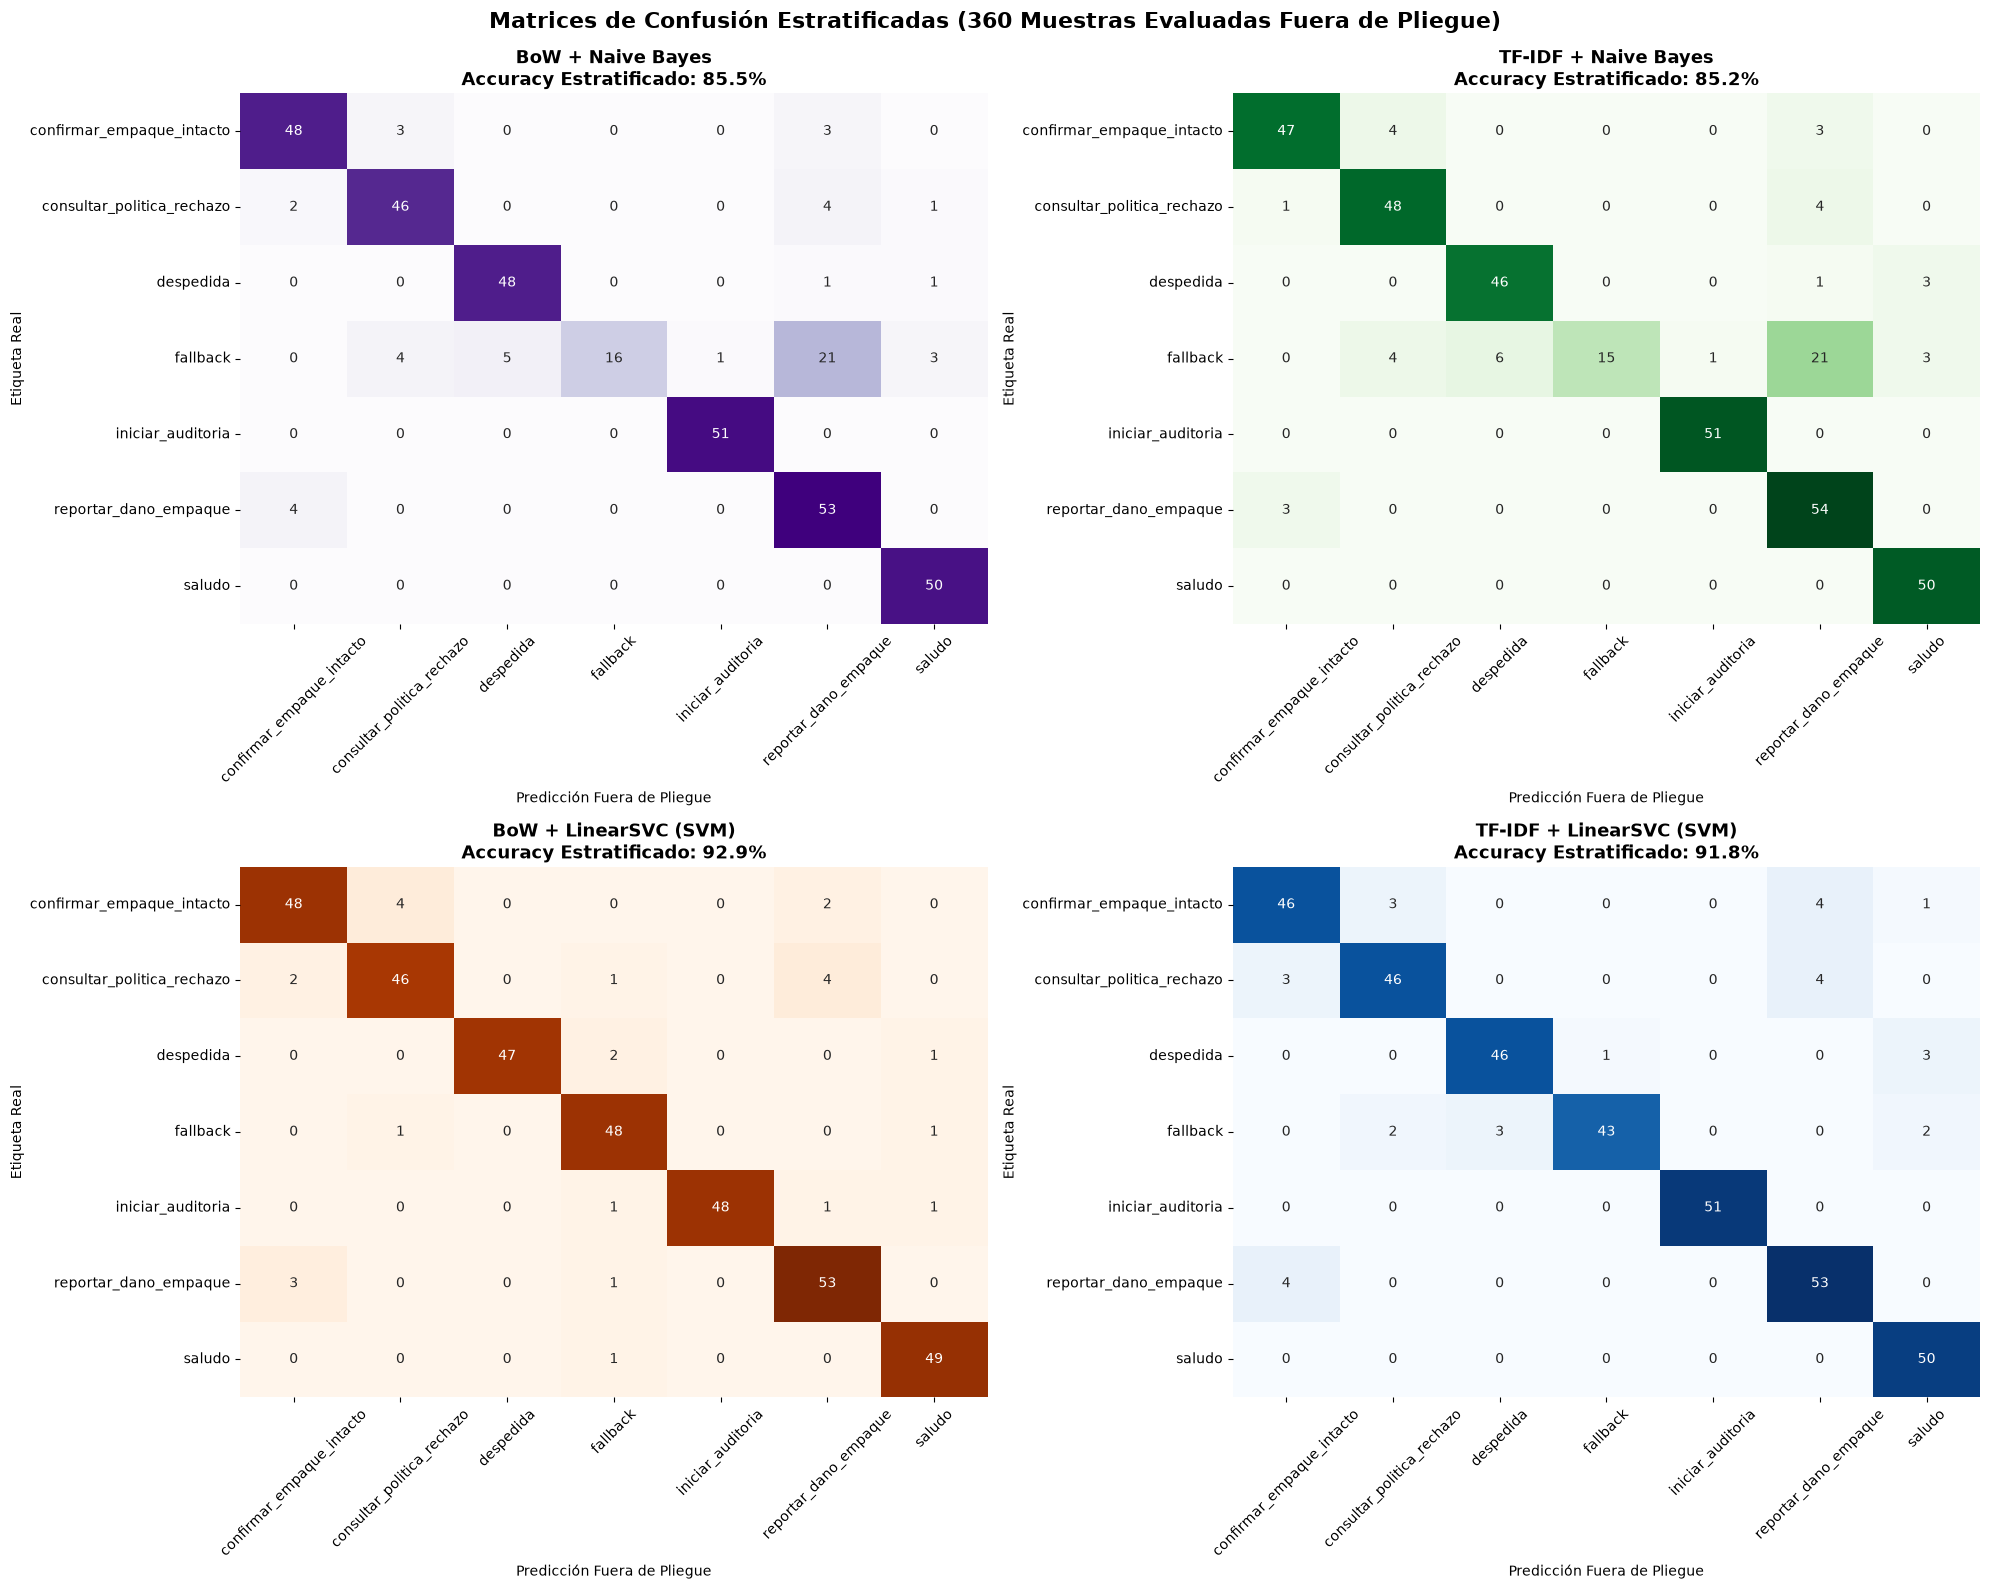

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict

# Obtener predicciones estratificadas fuera de pliegue para cada pipeline
predicciones_cv = {}
for nombre, pipe in crear_pipelines().items():
    predicciones_cv[nombre] = cross_val_predict(pipe, X, y, cv=cv, n_jobs=-1)

# Reporte detallado del modelo ganador
print("=" * 80)
print(f"REPORTE DETALLADO DE CLASIFICACIÓN ESTRATIFICADA — {mejor_combinacion}")
print("=" * 80)
print(classification_report(y, predicciones_cv[mejor_combinacion], zero_division=0))

# Visualización comparativa de las 4 matrices de confusión
clases = sorted(y.unique())
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
axes = axes.flatten()
paletas = ["Purples", "Greens", "Oranges", "Blues"]

for idx, (nombre, preds) in enumerate(predicciones_cv.items()):
    cm = confusion_matrix(y, preds, labels=clases)
    acc = (preds == y).mean()
    
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=paletas[idx],
        xticklabels=clases, yticklabels=clases, ax=axes[idx], cbar=False
    )
    axes[idx].set_title(f"{nombre}\nAccuracy Estratificado: {acc:.1%}", fontsize=13, fontweight="bold")
    axes[idx].set_xlabel("Predicción Fuera de Pliegue", fontsize=10)
    axes[idx].set_ylabel("Etiqueta Real", fontsize=10)
    axes[idx].tick_params(axis="x", rotation=45)

plt.suptitle("Matrices de Confusión Estratificadas (360 Muestras Evaluadas Fuera de Pliegue)", fontsize=16, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


## 6. Evaluación de Casos Límite (*Edge Cases*)
Evaluamos cómo responden los modelos ante variaciones lingüísticas complejas que causaban fallas en el motor de reglas simbólicas del Avance 1:
- **Erratas tipográficas** (p. ej., *aplastda* en vez de *aplastada*).
- **Sinónimos fuera del vocabulario rígido** (p. ej., *trae un hueco enorme*).
- **Presencia de palabras protegidas** (p. ej., *el bulto viene en mal estado*).
- **Empaque íntegro sin daño** (*todo el embarque llegó impecable y sellado*).


In [6]:
# Ajustamos los pipelines sobre el dataset completo para evaluar casos límite
pipelines_entrenados = {}
for nombre, pipe in crear_pipelines().items():
    pipe.fit(X, y)
    pipelines_entrenados[nombre] = pipe

casos_limite = [
    ("Errata en palabra clave", "la caja esta aplastda", "reportar_dano_empaque"),
    ("Sinónimo fuera de diccionario", "la caja trae un hueco enorme", "reportar_dano_empaque"),
    ("Variación con 'estado'", "el bulto viene en mal estado", "reportar_dano_empaque"),
    ("Empaque íntegro sin daño", "todo el embarque llegó impecable y sellado", "confirmar_empaque_intacto"),
    ("Mensaje ambiguo / desconocido", "hay una caja pero no se si esta bien", "reportar_dano_empaque")
]

res_limites = []
for caso, entrada, esperada in casos_limite:
    fila = {
        "Caso de Prueba": caso,
        "Entrada del Inspector": entrada,
        "Intención Esperada": esperada
    }
    for nombre, pipe in pipelines_entrenados.items():
        pred = pipe.predict([entrada])[0]
        marca = "✔" if pred == esperada else "✘"
        fila[nombre] = f"{pred} {marca}"
    res_limites.append(fila)

df_limites = pd.DataFrame(res_limites)
display(df_limites)


,Caso de Prueba,Entrada del Inspector,Intención Esperada,BoW + Naive Bayes,TF-IDF + Naive Bayes,BoW + LinearSVC (SVM),TF-IDF + LinearSVC (SVM)
0,Errata en palabra clave,la caja esta aplastda,reportar_dano_empaque,reportar_dano_empaque ✔,reportar_dano_empaque ✔,reportar_dano_empaque ✔,reportar_dano_empaque ✔
1,Sinónimo fuera de diccionario,la caja trae un hueco enorme,reportar_dano_empaque,reportar_dano_empaque ✔,reportar_dano_empaque ✔,reportar_dano_empaque ✔,reportar_dano_empaque ✔
2,Variación con 'estado',el bulto viene en mal estado,reportar_dano_empaque,reportar_dano_empaque ✔,reportar_dano_empaque ✔,reportar_dano_empaque ✔,reportar_dano_empaque ✔
3,Empaque íntegro sin daño,todo el embarque llegó impecable y sellado,confirmar_empaque_intacto,confirmar_empaque_intacto ✔,confirmar_empaque_intacto ✔,confirmar_empaque_intacto ✔,confirmar_empaque_intacto ✔
4,Mensaje ambiguo / desconocido,hay una caja pero no se si esta bien,reportar_dano_empaque,confirmar_empaque_intacto ✘,confirmar_empaque_intacto ✘,confirmar_empaque_intacto ✘,confirmar_empaque_intacto ✘


## 7. Persistencia y Exportación del Pipeline Ganador
El modelo ganador validado por las pruebas estratificadas se reentrena con el 100% de las muestras (`X`, `y`) y se serializa a disco con `joblib`.
Este artefacto será importado por el clasificador ML (`MLIntentClassifier`) dentro del motor del asistente (`src/chatbot_engine.py`).


In [7]:
from pathlib import Path

import joblib

# Directorio de persistencia
dir_modelos = Path("models")
dir_modelos.mkdir(parents=True, exist_ok=True)
ruta_export = dir_modelos / "pipeline_intenciones.joblib"

# Entrenar el pipeline ganador con todos los datos
modelo_final = crear_pipelines()[mejor_combinacion]
modelo_final.fit(X, y)

# Guardar en disco
joblib.dump(modelo_final, ruta_export)
print(f"[OK] Pipeline '{mejor_combinacion}' exportado exitosamente en: {ruta_export}")

# Verificación de recarga y predicción
modelo_cargado = joblib.load(ruta_export)
prueba_texto = "El paquete tiene una rasgadura en la cinta de seguridad"
pred_prueba = modelo_cargado.predict([prueba_texto])[0]
print("\nPrueba de verificación con modelo recargado:")
print(f"  Entrada   : '{prueba_texto}'")
print(f"  Predicción: '{pred_prueba}'")


[OK] Pipeline 'BoW + LinearSVC (SVM)' exportado exitosamente en: models\pipeline_intenciones.joblib

Prueba de verificación con modelo recargado:
  Entrada   : 'El paquete tiene una rasgadura en la cinta de seguridad'
  Predicción: 'reportar_dano_empaque'
